# Customer Churn Prediction — Telco Dataset
**Business question:** *Which customers are most likely to leave, and why?*

**Project roadmap**
1. **Data loading & cleaning** ← *this stage*
2. Exploratory Data Analysis (EDA)
3. Machine learning (baseline → better models)
4. Interpreting the model & answering the business question

**Dataset:** IBM Telco Customer Churn — 7,043 customers of a fictional telecom company. Each row is a customer;
`Churn = Yes` means they left in the last month.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load the data
First look: how big is it, and what does a row look like?

In [2]:
df = pd.read_csv("telco_churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Understand the columns
Before cleaning anything, group the columns by what they *mean*. This shapes every later decision.

| Group | Columns |
|---|---|
| ID | `customerID` (not a feature — just a label) |
| Demographics | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Account | `tenure` (months as a customer), `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges` |
| Services | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| **Target** | `Churn` (Yes/No) — what we want to predict |

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Spot the problem:** `TotalCharges` should be a number (money), but pandas read it as text (`object`/`str`).
That almost always means some values aren't valid numbers. Let's find them.

In [4]:
tc_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")  # invalid -> NaN
bad = df[tc_numeric.isna()]
print(f"{len(bad)} rows have a non-numeric TotalCharges")
bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

11 rows have a non-numeric TotalCharges


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


**Detective work:** every one of these rows has `tenure = 0` — brand-new customers who haven't been billed yet.
So the blank isn't *missing* data, it really means **0**. Filling with 0 is more accurate than dropping the rows or using the average.

> Lesson: always ask *why* data is missing before choosing how to fix it.

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["TotalCharges"].dtype

dtype('float64')

## 4. Other quality checks: missing values, duplicates, odd categories

In [6]:
print("Missing values per column:", df.isna().sum().sum())
print("Duplicate customer IDs:  ", df["customerID"].duplicated().sum())

Missing values per column: 0
Duplicate customer IDs:   0


In [7]:
# Look at every categorical column's unique values to catch typos / odd labels
for col in df.select_dtypes(exclude="number").columns.drop("customerID"):
    print(f"{col:18} {sorted(df[col].unique())}")

gender             ['Female', 'Male']
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn              ['No', 'Yes']


Two things to notice:
- **`SeniorCitizen`** is stored as 0/1 while every other yes/no column uses `"Yes"`/`"No"`. We'll make it consistent.
- Labels like **`"No internet service"`** and **`"No phone service"`** appear in the service columns. For a customer without internet,
  "No internet service" effectively means "No" for `OnlineSecurity` etc. — and that info is already captured by `InternetService = "No"`.
  Collapsing them to `"No"` reduces redundant categories. (We keep the raw copy in case EDA shows it matters.)

In [8]:
df_raw = df.copy()   # keep an untouched copy for reference

df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

no_service_cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                   "TechSupport", "StreamingTV", "StreamingMovies"]
for col in no_service_cols:
    df[col] = df[col].replace({"No internet service": "No", "No phone service": "No"})

df[no_service_cols].apply(lambda s: s.unique())

,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,No,No,Yes,No,No,No,No
1,Yes,Yes,No,Yes,Yes,Yes,Yes


## 5. Sanity-check the numbers
`TotalCharges` should be roughly `tenure × MonthlyCharges`. If it's wildly off for some rows, that's a data problem.

In [9]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(1)

,tenure,MonthlyCharges,TotalCharges
count,7043.0,7043.0,7043.0
mean,32.4,64.8,2279.7
std,24.6,30.1,2266.8
min,0.0,18.2,0.0
25%,9.0,35.5,398.6
50%,29.0,70.4,1394.6
75%,55.0,89.8,3786.6
max,72.0,118.8,8684.8


In [10]:
expected = df["tenure"] * df["MonthlyCharges"]
ratio = (df["TotalCharges"] / expected).replace([np.inf, -np.inf], np.nan)
print(ratio.describe().round(2))

count    7032.00
mean        1.00
std         0.05
min         0.69
25%         0.98
50%         1.00
75%         1.02
max         1.57
dtype: float64


The ratio centres around 1.0 with a tight spread — prices change a bit over time, but nothing broken. No outliers to fix.

## 6. The target: how imbalanced is it?

In [11]:
df["Churn"].value_counts(normalize=True).round(3)

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64

About **26.5% churned**. This is a *mildly imbalanced* target, which matters later:
a lazy model that predicts "No" for everyone would be **73.5% accurate** and completely useless.
So accuracy alone won't be our metric — we'll look at **recall, precision and ROC-AUC**.

## 7. Save the clean dataset

In [12]:
df["Churn"] = (df["Churn"] == "Yes").astype(int)   # 1 = churned, 0 = stayed (ML-friendly)
df.to_csv("telco_churn_clean.csv", index=False)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## ✅ Stage 1 summary
| Issue found | Fix | Why |
|---|---|---|
| `TotalCharges` stored as text, 11 blanks | Converted to number, blanks → 0 | All blanks were tenure-0 customers (not billed yet) |
| `SeniorCitizen` as 0/1 | Mapped to Yes/No | Consistent with other columns |
| "No internet/phone service" labels | Collapsed to "No" | Redundant with `InternetService` / `PhoneService` |
| `Churn` as Yes/No | Mapped to 1/0 | Models need numbers |
| Missing values / duplicates | None found | — |

**Next — Stage 2 (EDA):** which customer traits are linked to churn?

---
# Stage 2 — Exploratory Data Analysis (EDA)
**Goal:** find which customer traits are associated with churn *before* building any model.
EDA gives us hypotheses ("month-to-month customers leave more") that the model will later confirm or challenge.

**Approach:** for each feature, compare the **churn rate** inside each group against the overall rate (26.5%).
A group far above the average line is a risk signal.

## 1. Chart setup

In [13]:
df = pd.read_csv("telco_churn_clean.csv")
OVERALL = df["Churn"].mean()

# Two colours, used consistently: blue = stayed, orange = churned (checked to be colour-blind safe)
STAYED, CHURNED = "#2a78d6", "#eb6834"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.edgecolor": "#d0d0cc", "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": "#ececea",
                     "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left"})

def churn_rate_bar(col, ax=None, order=None, title=None):
    """Horizontal bars of churn rate per category, with the overall average as a dashed line."""
    ax = ax or plt.subplots(figsize=(7, 0.6 * df[col].nunique() + 1))[1]
    rates = df.groupby(col)["Churn"].agg(["mean", "size"])
    rates = rates.loc[order] if order else rates.sort_values("mean")
    ax.barh(rates.index.astype(str), rates["mean"], color=CHURNED, height=0.6)
    ax.axvline(OVERALL, color=MUTED, ls="--", lw=1)
    for i, (r, n) in enumerate(zip(rates["mean"], rates["size"])):
        ax.text(r + 0.01, i, f"{r:.0%}  (n={n:,})", va="center", fontsize=9, color=INK)
    ax.set_xlim(0, max(0.6, rates["mean"].max() + 0.15))
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.set_title(title or f"Churn rate by {col}"); ax.set_xlabel(f"dashed line = overall average ({OVERALL:.1%})", fontsize=9)
    ax.grid(axis="y", visible=False)
    sns.despine(ax=ax, left=True)
    return ax

## 2. Contract type — the strongest signal

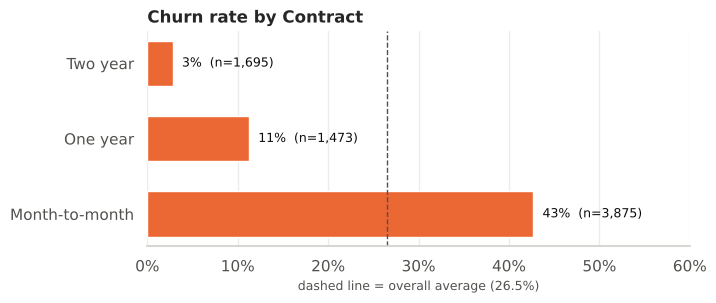

In [14]:
churn_rate_bar("Contract", order=["Month-to-month", "One year", "Two year"]); plt.show()

**Month-to-month customers churn at ~43%**, versus ~3% on two-year contracts — a **15× difference**.
That makes sense: nothing locks them in, so leaving is easy.

> 💡 Business idea: offer incentives to move month-to-month customers onto annual contracts.

## 3. Tenure — new customers are the most at risk
`tenure` is numeric, so first compare the *distributions* of stayers vs leavers, then bucket it into churn rates.

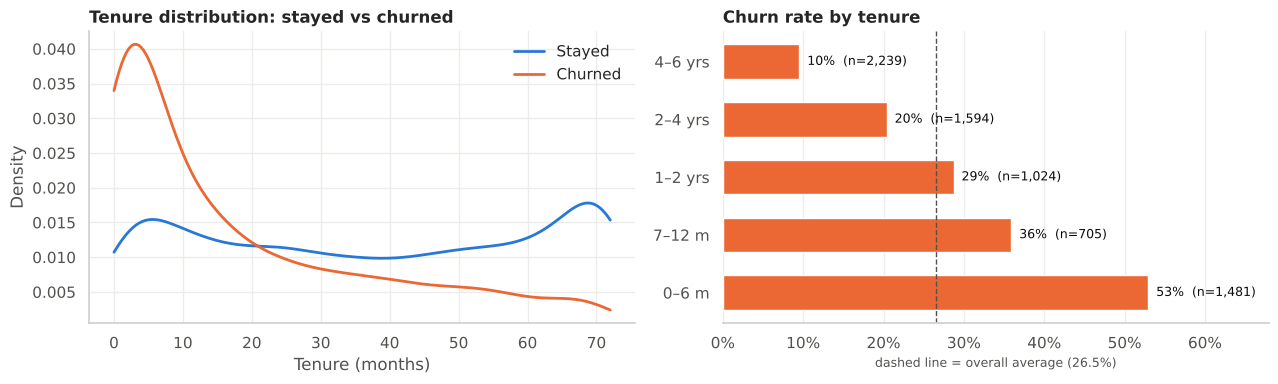

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for label, colour, val in [("Stayed", STAYED, 0), ("Churned", CHURNED, 1)]:
    sns.kdeplot(df.loc[df.Churn == val, "tenure"], ax=axes[0], color=colour, lw=2, label=label, clip=(0, 72))
axes[0].set_title("Tenure distribution: stayed vs churned"); axes[0].set_xlabel("Tenure (months)")
axes[0].legend(frameon=False); sns.despine(ax=axes[0])

df["tenure_group"] = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72],
                            labels=["0–6 m", "7–12 m", "1–2 yrs", "2–4 yrs", "4–6 yrs"])
churn_rate_bar("tenure_group", ax=axes[1], title="Churn rate by tenure", order=["0–6 m", "7–12 m", "1–2 yrs", "2–4 yrs", "4–6 yrs"])
plt.tight_layout(); plt.show()

Churners cluster heavily in the **first few months** (orange peak on the left), while stayers spread out to 70+ months.
**More than half of customers in their first 6 months leave**; after 4 years it drops below 10%.

> 💡 The first 6 months are the danger zone → onboarding and early-life engagement matter most.

## 4. Monthly charges — leavers pay more

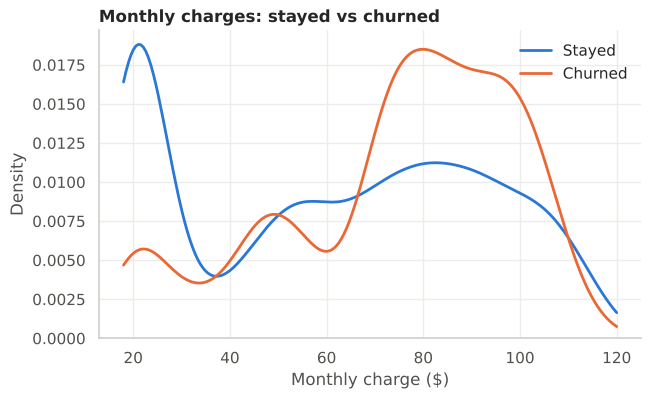

,tenure,MonthlyCharges,TotalCharges
Churn,,,
Stayed,38.0,64.425,1679.525
Churned,10.0,79.650,703.550


In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
for label, colour, val in [("Stayed", STAYED, 0), ("Churned", CHURNED, 1)]:
    sns.kdeplot(df.loc[df.Churn == val, "MonthlyCharges"], ax=ax, color=colour, lw=2, label=label, clip=(18, 120))
ax.set_title("Monthly charges: stayed vs churned"); ax.set_xlabel("Monthly charge ($)")
ax.legend(frameon=False); sns.despine(); plt.show()

df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].median().rename(index={0: "Stayed", 1: "Churned"})

Stayers peak around **$20** (basic plans), while churners concentrate in the **$70–$105** range.
Median monthly charge: churned ≈ $80 vs stayed ≈ $64.

Note that churners have *lower* `TotalCharges` — not because they're cheap, but because they leave early (low tenure).
This is a classic trap: always ask what's *driving* a pattern.

## 5. Services: internet type and support add-ons

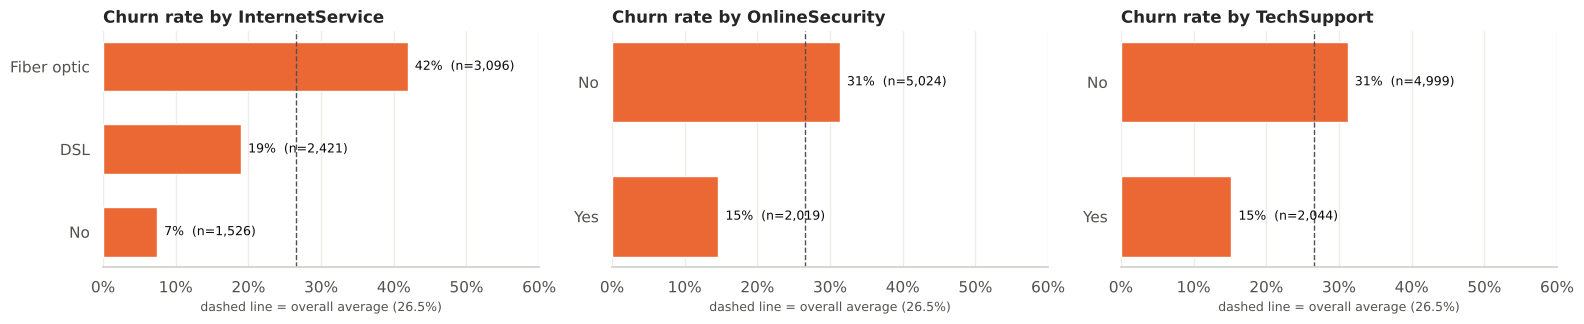

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
churn_rate_bar("InternetService", ax=axes[0])
churn_rate_bar("OnlineSecurity", ax=axes[1])
churn_rate_bar("TechSupport", ax=axes[2])
plt.tight_layout(); plt.show()

- **Fiber-optic customers churn at ~42%**, more than double DSL (~19%). Fiber is the premium (most expensive) product,
  so this may be a **price/value** problem, or a service-quality one — EDA can't tell us which. That's a question for the business.
- Customers **without Online Security or Tech Support** churn at ~31%, about double those who have them.
  These "sticky" services seem to help customers feel supported.

## 6. Billing & payment method

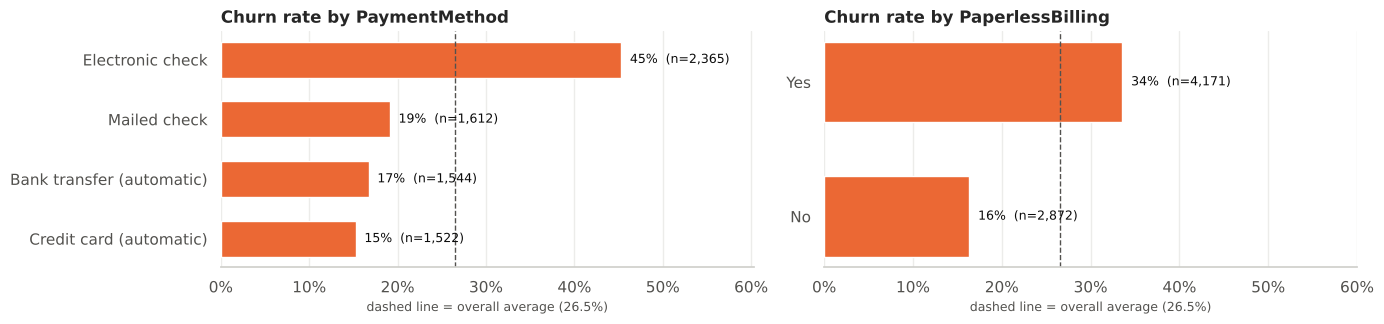

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
churn_rate_bar("PaymentMethod", ax=axes[0])
churn_rate_bar("PaperlessBilling", ax=axes[1])
plt.tight_layout(); plt.show()

**Electronic check** users churn at ~45% — far above the automatic payment methods (~15–17%).
Automatic payments create a "set and forget" habit; manual payment means a monthly moment to reconsider.

## 7. Demographics

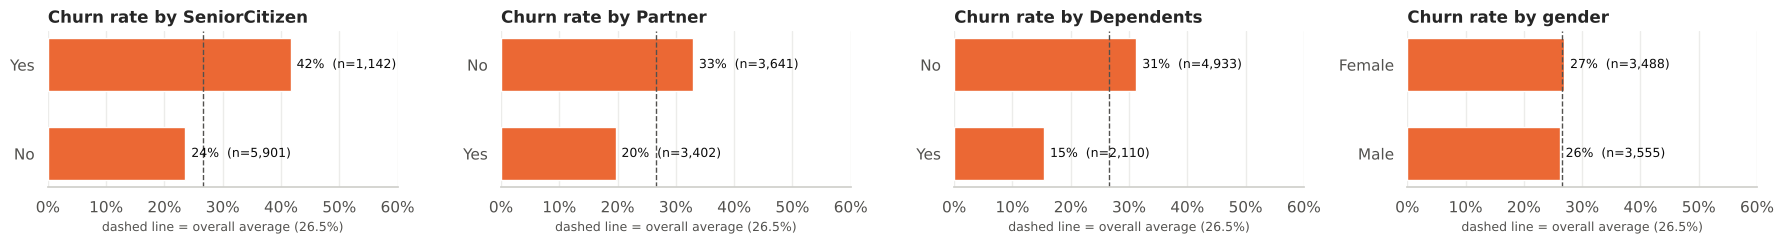

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(18, 2.6))
for ax, col in zip(axes, ["SeniorCitizen", "Partner", "Dependents", "gender"]):
    churn_rate_bar(col, ax=ax)
plt.tight_layout(); plt.show()

- **Senior citizens** churn more (~42% vs ~24%).
- Customers **without a partner or dependents** churn more — single-person households have fewer ties.
- **Gender makes no difference** (26.9% vs 26.2%). A useful finding: some features carry no signal, and we may drop them.

## 8. Ranking every feature at once
Which features separate churners best? A simple measure: the **gap** between the highest and lowest churn rate across a feature's groups.

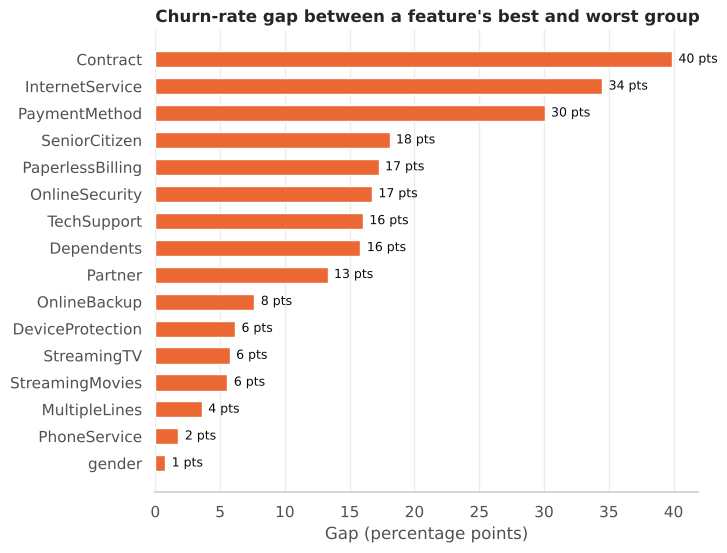

In [20]:
cat_cols = [c for c in df.select_dtypes(exclude="number").columns if c not in ("customerID", "tenure_group")]
spread = pd.Series({c: df.groupby(c)["Churn"].mean().agg(lambda s: s.max() - s.min()) for c in cat_cols}).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(spread.index, spread.values, color=CHURNED, height=0.6)
for i, v in enumerate(spread.values):
    ax.text(v + 0.005, i, f"{v*100:.0f} pts", va="center", fontsize=9, color=INK)
ax.set_title("Churn-rate gap between a feature's best and worst group")
ax.set_xlabel("Gap (percentage points)"); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda x, _: f"{x*100:.0f}"))
sns.despine(left=True); plt.show()

Top three: **Contract, InternetService, PaymentMethod**. At the bottom, `gender`, `PhoneService` and `MultipleLines` barely matter.

## 9. Correlation between the numeric features

In [21]:
df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].corr().round(2)

,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.00,0.25,0.83,-0.35
MonthlyCharges,0.25,1.00,0.65,0.19
TotalCharges,0.83,0.65,1.00,-0.20
Churn,-0.35,0.19,-0.20,1.00


`TotalCharges` is strongly correlated with `tenure` (0.83) — it's roughly tenure × monthly charge, so it adds little new information.
When features overlap like this (**multicollinearity**), it can make some models (like logistic regression) harder to interpret.
We'll keep that in mind in Stage 3.

## 10. Putting it together: a high-risk segment
EDA looks at one feature at a time — but risk factors stack. What happens when we combine the top signals?

In [22]:
high_risk = (df["Contract"] == "Month-to-month") & (df["InternetService"] == "Fiber optic") & (df["tenure"] <= 12)
print(f"High-risk segment size:   {high_risk.sum():,} customers ({high_risk.mean():.0%} of base)")
print(f"Churn rate in segment:    {df.loc[high_risk, 'Churn'].mean():.0%}")
print(f"Share of ALL churners:    {df.loc[high_risk, 'Churn'].sum() / df['Churn'].sum():.0%}")

High-risk segment size:   916 customers (13% of base)
Churn rate in segment:    70%
Share of ALL churners:    34%


**Month-to-month + fiber + first year:** about 13% of customers, but **~70% of them churn** and they account for **about a third of all churners**.
That's a concrete, targetable group — and a preview of what a model does automatically: combine many signals into one risk score per customer.

## ✅ Stage 2 summary — hypotheses to test with ML
| Signal | Higher-risk group | Churn rate |
|---|---|---|
| Contract | Month-to-month | ~43% (vs 3% two-year) |
| Tenure | First 6 months | ~53% |
| Internet | Fiber optic | ~42% |
| Payment | Electronic check | ~45% |
| Add-ons | No Online Security / Tech Support | ~31% |
| Demographics | Senior, no partner/dependents | ~31–42% |
| **No signal** | Gender, phone service | ≈ average |

⚠️ **Correlation ≠ causation.** These are associations. For example, fiber customers may churn because of price, not the fibre itself.

**Next — Stage 3 (ML):** encode the features, split train/test, build a baseline logistic regression, then try tree-based models and compare them on recall, precision and ROC-AUC.

---
# Stage 3 — Machine Learning
**Goal:** give every customer a **churn probability** (0–1), and check how well it ranks customers who actually leave.

**Plan**
1. Prepare features (turn text into numbers) and hold back a test set
2. A "dumb" baseline, so we know what *useless* looks like
3. Logistic regression → random forest → gradient boosting, compared fairly with cross-validation
4. Pick a model, then choose the **decision threshold** that fits the business
5. Save the model for Stage 4

## 1. Features and target

In [23]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve, precision_recall_curve)

df = pd.read_csv("telco_churn_clean.csv")
X = df.drop(columns=["customerID", "Churn"])   # ID is just a label, not a behaviour
y = df["Churn"]

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]
print(f"{len(num_cols)} numeric + {len(cat_cols)} categorical features")

3 numeric + 16 categorical features


## 2. Train/test split
We lock away **20% of customers** as a test set and never touch it until the very end. It plays the role of
"future customers the model has never seen". `stratify=y` keeps the 26.5% churn rate the same in both parts.

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Train: {len(X_train):,} customers, churn {y_train.mean():.1%}")
print(f"Test:  {len(X_test):,} customers, churn {y_test.mean():.1%}")

Train: 5,634 customers, churn 26.5%
Test:  1,409 customers, churn 26.5%


## 3. Preprocessing: turning columns into numbers
Models only understand numbers, so:
- **Categorical** → **one-hot encoding**: `Contract` becomes three 0/1 columns (`Contract_Month-to-month`, `Contract_One year`, `Contract_Two year`).
  Yes/No columns become a single 0/1 column (`drop="if_binary"`).
- **Numeric** → **standard scaling** (mean 0, std 1), so `TotalCharges` (in thousands) doesn't drown out `tenure` (in tens).

We wrap this in a `Pipeline`. That way the scaler learns its averages **from the training data only**,
so no information leaks in from the test set. (**Data leakage** is one of the most common ML mistakes.)

In [25]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
])
n_features = preprocess.fit(X_train).transform(X_train[:1]).shape[1]
print(f"{X.shape[1]} original columns → {n_features} model features")

19 original columns → 26 model features


## 4. Metrics, in plain language
| Metric | Question it answers |
|---|---|
| **Recall** | Of the customers who *actually* left, what % did we catch? |
| **Precision** | Of the customers we *flagged*, what % actually left? (wasted retention offers = low precision) |
| **F1** | One number that balances precision and recall |
| **ROC-AUC** | Pick one leaver and one stayer at random. How often does the model give the leaver a higher risk score? 0.5 = coin flip, 1.0 = perfect |

ROC-AUC doesn't depend on any threshold, so it's our main score for **comparing models**.
Precision and recall depend on where we draw the line, and we'll tune that in step 7.

## 5. Baseline: a model that predicts "nobody leaves"

In [26]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["roc_auc", "accuracy", "precision", "recall", "f1"]

def evaluate(name, estimator):
    pipe = Pipeline([("prep", preprocess), ("model", estimator)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    return {"model": name, **{m: s[f"test_{m}"].mean() for m in scoring}, "auc_std": s["test_roc_auc"].std()}

import warnings; warnings.filterwarnings("ignore")   # dummy model has 0 precision → warning
results = [evaluate("Baseline (always 'No')", DummyClassifier(strategy="most_frequent"))]
pd.DataFrame(results).round(3)

,model,roc_auc,accuracy,precision,recall,f1,auc_std
0,Baseline (always 'No'),0.5,0.735,0.0,0.0,0.0,0.0


**73.5% accuracy, 0% recall.** It catches no churners at all. This is why we said accuracy alone would mislead us.
Any real model has to beat **ROC-AUC 0.5** by a clear margin.

## 6. Real models, compared with 5-fold cross-validation
**Cross-validation:** we split the *training* set into 5 parts, train on 4 and score on the 5th, then rotate through all 5.
This gives 5 scores per model instead of 1, so we can see if a difference is real or just luck.

We try:
- **Logistic regression**: a weighted sum of features turned into a probability. Simple and easy to explain.
- **Logistic regression (balanced)**: same model, but mistakes on churners count ~3× more, to make up for them being the minority.
- **Random forest**: hundreds of decision trees that vote.
- **Gradient boosting**: trees built one after another, each fixing the previous one's mistakes.

In [27]:
candidates = {
    "Logistic regression":            LogisticRegression(max_iter=1000),
    "Logistic regression (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random forest (balanced)":       RandomForestClassifier(n_estimators=300, min_samples_leaf=10,
                                                             class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient boosting":              GradientBoostingClassifier(n_estimators=200, max_depth=3,
                                                                 learning_rate=0.05, random_state=42),
}
for name, est in candidates.items():
    results.append(evaluate(name, est))

comparison = pd.DataFrame(results).set_index("model").round(3)
comparison

,roc_auc,accuracy,precision,recall,f1,auc_std
model,,,,,,
Baseline (always 'No'),0.500,0.735,0.000,0.000,0.000,0.000
Logistic regression,0.846,0.802,0.654,0.543,0.593,0.012
Logistic regression (balanced),0.846,0.749,0.518,0.803,0.629,0.012
Random forest (balanced),0.847,0.759,0.531,0.782,0.632,0.011
Gradient boosting,0.848,0.802,0.664,0.521,0.583,0.012


### What this table teaches
1. **Every real model reaches ROC-AUC ≈ 0.845**, and the gaps (≈0.002) are far smaller than the run-to-run noise (`auc_std` ≈ 0.012).
   **The fancy tree models are not better here.** This happens often with clean, tabular business data.
2. **The big differences are in recall vs precision**, and they come from `class_weight="balanced"`, not from the algorithm.
   Balanced models catch **~80% of churners** (but with more false alarms). Unbalanced ones catch only ~53%.
3. Accuracy goes *down* for the balanced models. More proof that accuracy is the wrong target here.

**Decision: balanced logistic regression.** It's as accurate as the others, trains instantly, and each feature has a clear
coefficient we can explain to a business audience, which is exactly what Stage 4 needs.

> Lesson: start simple. Only use a complex model when it *clearly* beats the simple one.

## 7. Final check on the untouched test set

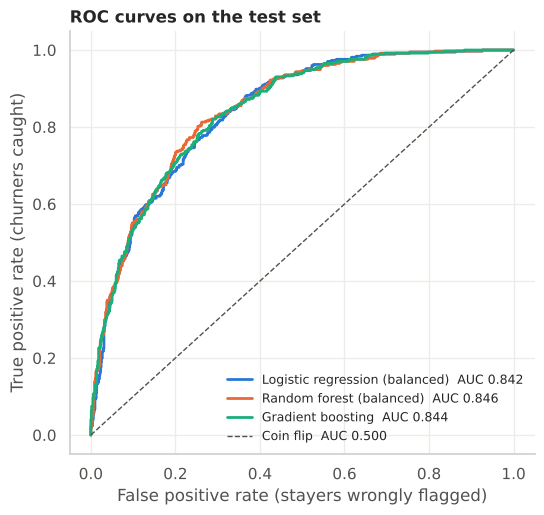

In [28]:
final_model = Pipeline([("prep", preprocess),
                        ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))])
final_model.fit(X_train, y_train)
p_test = final_model.predict_proba(X_test)[:, 1]   # churn probability for each test customer

# Fit the comparison models too, just to draw their ROC curves
others = {n: Pipeline([("prep", preprocess), ("model", candidates[n])]).fit(X_train, y_train)
          for n in ["Random forest (balanced)", "Gradient boosting"]}

fig, ax = plt.subplots(figsize=(6, 5.5))
curves = [("Logistic regression (balanced)", p_test, STAYED)] + \
         [(n, m.predict_proba(X_test)[:, 1], c) for (n, m), c in zip(others.items(), [CHURNED, "#1baf7a"])]
for name, p, colour in curves:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=colour, lw=2, label=f"{name}  AUC {roc_auc_score(y_test, p):.3f}")
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1, label="Coin flip  AUC 0.500")
ax.set_xlabel("False positive rate (stayers wrongly flagged)")
ax.set_ylabel("True positive rate (churners caught)")
ax.set_title("ROC curves on the test set")
ax.legend(frameon=False, fontsize=9, loc="lower right"); sns.despine(); plt.show()

The three curves almost overlap, which confirms the cross-validation result on brand-new data.
Test ROC-AUC ≈ **0.84**, close to the CV score, so the model is **not overfitting** (it hasn't just memorised the training data).

## 8. Choosing the decision threshold
The model outputs a probability. To act on it, we need a cut-off: "flag anyone above X".
- **Low threshold** → catch more churners (higher recall) but send more unneeded offers (lower precision)
- **High threshold** → fewer, more accurate flags, but more churners slip through

The right answer depends on **costs**: a retention discount might cost R100, while losing a customer might cost R1,500+ in revenue.
When missing a churner costs much more than a wasted offer, we lean towards **recall**.

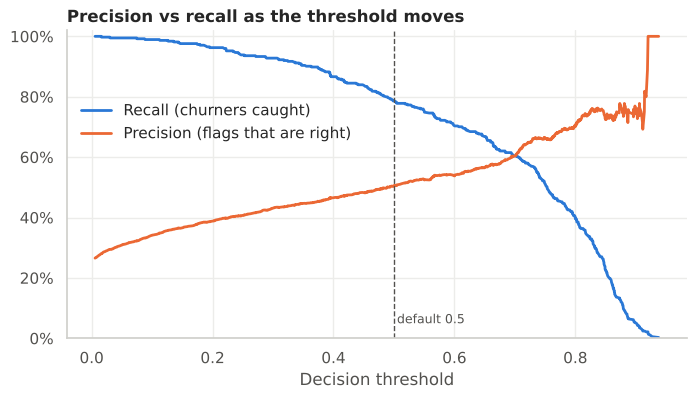

,customers flagged,recall,precision,f1
threshold,,,,
0.3,805,0.928,0.431,0.589
0.4,696,0.866,0.466,0.606
0.5,582,0.786,0.505,0.615
0.6,489,0.703,0.538,0.610
0.7,374,0.604,0.604,0.604


In [29]:
prec, rec, thr = precision_recall_curve(y_test, p_test)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thr, rec[:-1], color=STAYED, lw=2, label="Recall (churners caught)")
ax.plot(thr, prec[:-1], color=CHURNED, lw=2, label="Precision (flags that are right)")
ax.axvline(0.5, color=MUTED, ls="--", lw=1)
ax.text(0.505, 0.05, "default 0.5", color=MUTED, fontsize=9)
ax.set_xlabel("Decision threshold"); ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Precision vs recall as the threshold moves")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(0, 0.7)); sns.despine(); plt.show()

rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (p_test >= t).astype(int)
    rows.append({"threshold": t, "customers flagged": pred.sum(), "recall": recall_score(y_test, pred),
                 "precision": precision_score(y_test, pred), "f1": f1_score(y_test, pred)})
pd.DataFrame(rows).set_index("threshold").round(3)

Moving from 0.5 to 0.6 costs about **8 points of recall** but gains only **3 points of precision**, and F1 hardly changes between 0.4 and 0.7.
**0.5 is a reasonable default** when a missed churner costs much more than a wasted offer. If the retention budget is tight, raise the threshold.

## 9. Confusion matrix at threshold 0.5

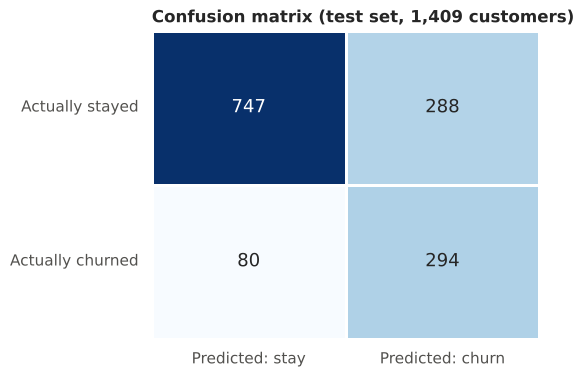

Caught 294 of 374 churners (79%); missed 80.
288 stayers would get an offer they didn't need.


In [30]:
pred = (p_test >= 0.5).astype(int)
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax, linewidths=2, linecolor="white",
            xticklabels=["Predicted: stay", "Predicted: churn"], yticklabels=["Actually stayed", "Actually churned"],
            annot_kws={"size": 13})
ax.set_title("Confusion matrix (test set, 1,409 customers)"); plt.yticks(rotation=0); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Caught {tp} of {tp+fn} churners ({tp/(tp+fn):.0%}); missed {fn}.")
print(f"{fp} stayers would get an offer they didn't need.")

## 10. Business view: how much does targeting help?
Say the retention team can only call the **top 20% riskiest customers**. What share of all churners would they reach?

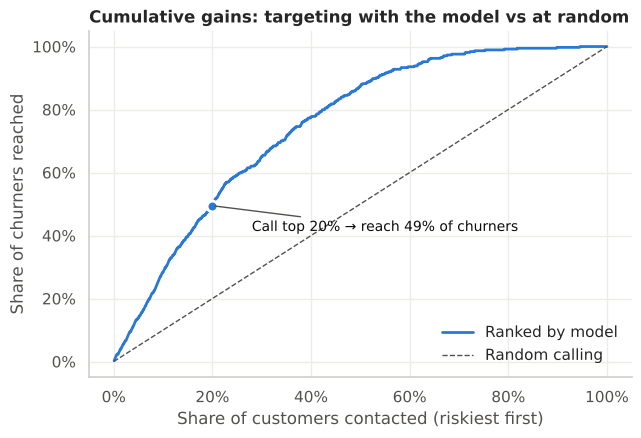

In [31]:
order = np.argsort(-p_test)
captured = np.cumsum(y_test.values[order]) / y_test.sum()
share_called = np.arange(1, len(order) + 1) / len(order)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(share_called, captured, color=STAYED, lw=2, label="Ranked by model")
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1, label="Random calling")
top20 = captured[int(0.2 * len(order)) - 1]
ax.scatter([0.2], [top20], color=STAYED, s=60, zorder=3, edgecolor="white", linewidth=2)
ax.annotate(f"Call top 20% → reach {top20:.0%} of churners", (0.2, top20), (0.28, top20 - 0.08),
            fontsize=10, color=INK, arrowprops=dict(arrowstyle="-", color=MUTED))
for a in (ax.xaxis, ax.yaxis): a.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Share of customers contacted (riskiest first)"); ax.set_ylabel("Share of churners reached")
ax.set_title("Cumulative gains: targeting with the model vs at random")
ax.legend(frameon=False, loc="lower right"); sns.despine(); plt.show()

This is the chart to show a manager. Calling the top 20% at random would reach 20% of churners.
Calling the model's top 20% reaches **about half of them**, so each retention call is ~2.5× more effective.

## 11. Save the model

In [32]:
import joblib
joblib.dump(final_model, "churn_model.joblib")
print("Saved churn_model.joblib")

Saved churn_model.joblib


## ✅ Stage 3 summary
| Step | Result |
|---|---|
| Baseline ("nobody leaves") | 73.5% accuracy, **0% recall**, useless |
| 4 models compared (5-fold CV) | All ≈ **0.845 ROC-AUC**; complex models gave no real gain |
| Chosen model | **Balanced logistic regression**: same accuracy, easy to explain |
| Test set | ROC-AUC ≈ 0.84, recall ≈ 79%, precision ≈ 50% at threshold 0.5 |
| Business impact | Top 20% riskiest customers hold ~half of all churners |

**Next — Stage 4:** open up the model. Which features push risk up or down, and by how much?
Then produce a ranked list of at-risk customers, each with the reasons behind their score. That answers *"who will leave, and why?"*

---
# Stage 4 — Interpreting the model: *who* will leave, and *why*?
A risk score alone isn't enough. A retention team needs to know **what to do** about each customer.
In this stage we:
1. Read the model's **coefficients**, which show how each feature pushes risk up or down
2. Measure **feature importance**: which features does the model rely on most?
3. **Explain individual customers**, giving the top reasons behind each person's score
4. Produce a **ranked at-risk list** of current customers
5. Turn it all into business recommendations

## 1. Retrain on all the data
Stage 3 held back 20% of customers to *measure* performance honestly. That's done. Before using a model for real,
the normal practice is to **refit it on all available data** with the same settings, so it learns from every customer.

In [33]:
import joblib
from sklearn.base import clone

model = clone(joblib.load("churn_model.joblib")).fit(X, y)
prep, logreg = model.named_steps["prep"], model.named_steps["model"]
feature_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
coefs = pd.Series(logreg.coef_[0], index=feature_names)
print(f"{len(coefs)} coefficients learned")

26 coefficients learned


## 2. What the coefficients mean
Logistic regression adds up `coefficient × feature value` to get a "risk score" (log-odds), then turns that into a probability.
- **Positive** coefficient → **raises** churn risk; **negative** → **lowers** it
- `exp(coefficient)` is the **odds multiplier**. For example, 2.4× means the odds of churning are 2.4 times higher

How to compare:
- **Yes/No features** (e.g. `TechSupport_Yes`) are compared with "No"
- **Features with 3+ groups** (e.g. `Contract`) get a coefficient for *every* group, so compare groups by their difference:
  month-to-month (+0.58) vs two-year (−0.86) → `exp(0.58 + 0.86)` ≈ **4.2× the odds**
- **Numeric features** are scaled, so a coefficient is the effect of a **1 standard deviation** increase (≈ 25 months of tenure, ≈ $30/month)

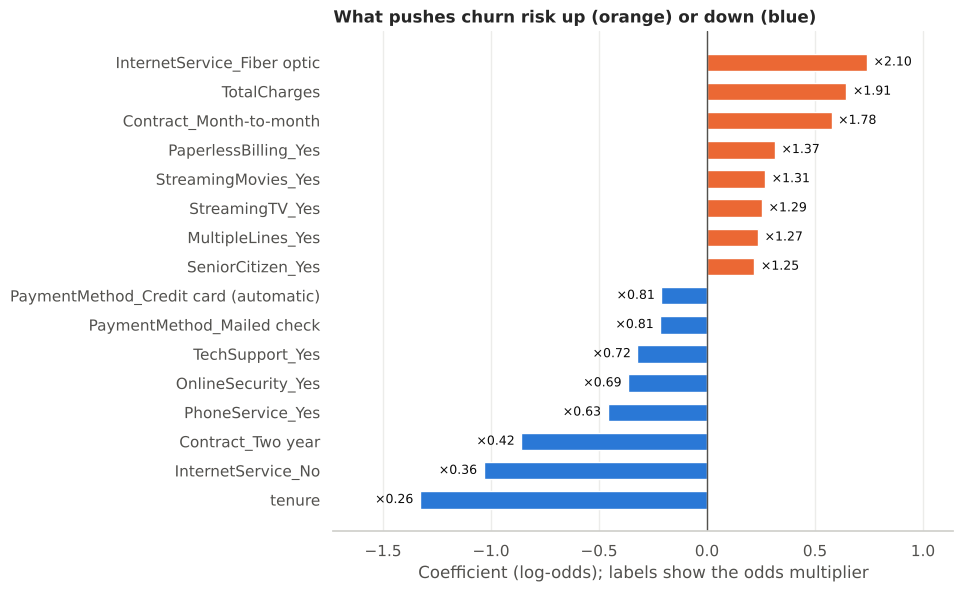

In [34]:
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index[:16]).sort_values()

fig, ax = plt.subplots(figsize=(8, 6.5))
colours = [CHURNED if v > 0 else STAYED for v in top.values]
ax.barh(top.index, top.values, color=colours, height=0.6)
ax.axvline(0, color=MUTED, lw=1)
for i, v in enumerate(top.values):
    ax.text(v + (0.03 if v > 0 else -0.03), i, f"×{np.exp(v):.2f}", va="center",
            ha="left" if v > 0 else "right", fontsize=9, color=INK)
ax.set_xlim(top.min() - 0.4, top.max() + 0.4)
ax.set_title("What pushes churn risk up (orange) or down (blue)")
ax.set_xlabel("Coefficient (log-odds); labels show the odds multiplier")
ax.grid(axis="y", visible=False); sns.despine(left=True); plt.show()

**Reading the chart:**
- 🟠 **Fiber optic** and **month-to-month contract** are the biggest risk raisers. Fiber has ~2.3× the odds of DSL; month-to-month has ~2× the odds of one-year and ~4× the odds of two-year
- 🔵 **Longer tenure** is the biggest protector: every extra ~2 years cuts the odds to about a quarter (×0.26)
- 🔵 **Two-year contract**, **no internet service**, **Online Security** and **Tech Support** all lower risk

### ⚠️ A trap worth understanding: the "wrong-looking" signs
`MonthlyCharges` has a *negative* coefficient and `TotalCharges` a *positive* one, which looks like the opposite of what EDA showed.
This is **multicollinearity** (we flagged it in Stage 2). Price is already captured by the services a customer has
(fiber, streaming…), and `TotalCharges` ≈ tenure × monthly charge. So each coefficient means *"the effect of this feature
**while holding all the others fixed**"*, a situation that rarely happens in real life.

Likewise, **Electronic check** looked huge in EDA (45% churn) but has a small coefficient here.
Much of its effect is "explained away" by contract and tenure, because electronic-check customers tend to be new and on month-to-month plans.

> Lesson: individual coefficients can mislead when features overlap. For "how much does the model rely on X?", use the next method.

## 3. Permutation importance: which features matter most?
A model-agnostic trick: **shuffle one column** so it becomes noise, and see how much ROC-AUC drops.
A big drop means the model really depends on that feature. We use the Stage 3 test set and shuffle each
*original* column (all of `Contract` together), so overlapping one-hot columns aren't split up.

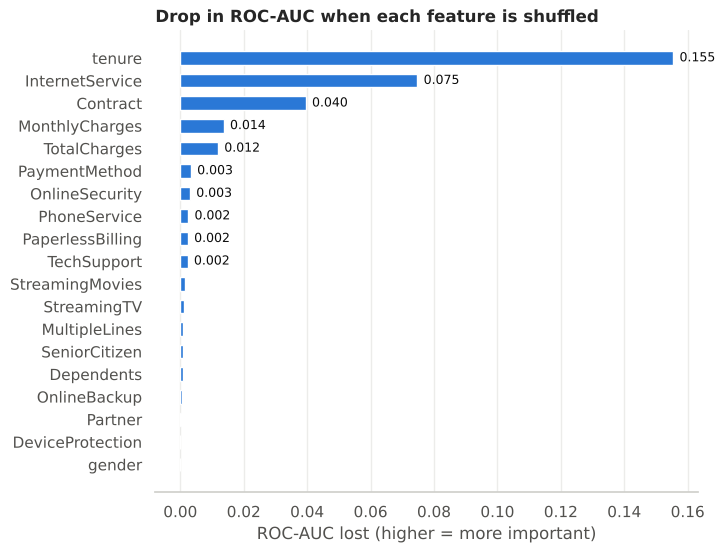

In [35]:
from sklearn.inspection import permutation_importance

test_model = joblib.load("churn_model.joblib")       # the Stage 3 model, never trained on X_test
pi = permutation_importance(test_model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42)
importance = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(importance.index, importance.values, color=STAYED, height=0.6)
for i, v in enumerate(importance.values):
    if v > 0.002:
        ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9, color=INK)
ax.set_title("Drop in ROC-AUC when each feature is shuffled")
ax.set_xlabel("ROC-AUC lost (higher = more important)")
ax.grid(axis="y", visible=False); sns.despine(left=True); plt.show()

**Tenure dominates**: shuffling it costs ~0.16 AUC. Next come **InternetService** and **Contract**.
Everything below `TotalCharges` adds very little. `gender`, `Partner` and `DeviceProtection` add essentially nothing,
which matches what EDA told us. A simpler model using only the top ~6 features would likely perform almost as well.

## 4. Explaining one customer at a time
For a linear model, each customer's score is a sum of pieces, so we can split it exactly:

> **contribution of a feature = coefficient × (this customer's value − the average customer's value)**

Positive pieces push this customer's risk **above average**; negative pieces pull it below. We add up the one-hot pieces
for each original column (e.g. all `Contract_*` columns) to get one reason per column.

In [36]:
Z = prep.transform(X)                                   # customers in model-feature space
Z = Z.toarray() if hasattr(Z, "toarray") else Z
contrib_raw = (Z - Z.mean(axis=0)) * logreg.coef_[0]    # one column per model feature

# Map each model feature back to its original column and sum
orig_of = {f: next(c for c in X.columns if f == c or f.startswith(c + "_")) for f in feature_names}
contrib = pd.DataFrame(contrib_raw, columns=feature_names, index=df["customerID"]).T \
            .groupby(orig_of).sum().T
df["churn_prob"] = model.predict_proba(X)[:, 1]
contrib.iloc[:3].round(2)

,Contract,Dependents,DeviceProtection,InternetService,MonthlyCharges,MultipleLines,OnlineBackup,OnlineSecurity,PaperlessBilling,Partner,PaymentMethod,PhoneService,SeniorCitizen,StreamingMovies,StreamingTV,TechSupport,TotalCharges,gender,tenure
customerID,,,,,,,,,,,,,,,,,,,
7590-VHVEG,0.49,0.05,0.02,-0.17,0.19,-0.1,-0.09,0.10,0.13,-0.01,0.25,0.42,-0.04,-0.1,-0.1,0.09,-0.64,0.01,1.70
5575-GNVDE,-0.20,0.05,-0.03,-0.17,0.04,-0.1,0.05,-0.26,-0.19,0.01,-0.15,-0.04,-0.04,-0.1,-0.1,0.09,-0.11,-0.01,-0.09
3668-QPYBK,0.49,0.05,0.02,-0.17,0.06,-0.1,-0.09,-0.26,0.13,0.01,-0.15,-0.04,-0.04,-0.1,-0.1,0.09,-0.62,-0.01,1.64


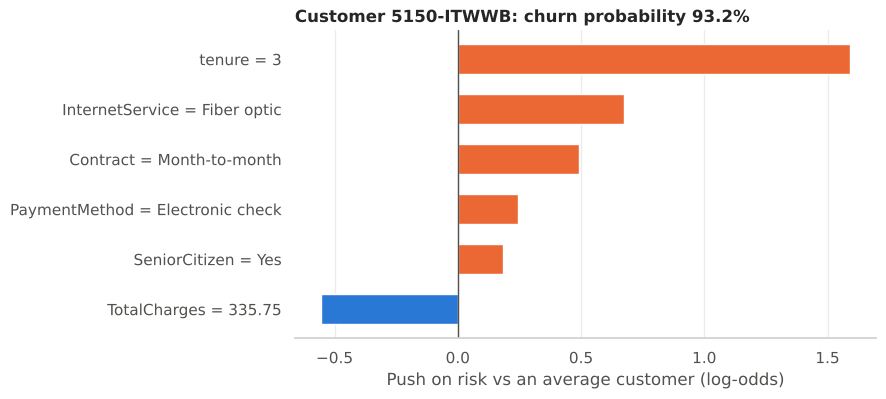

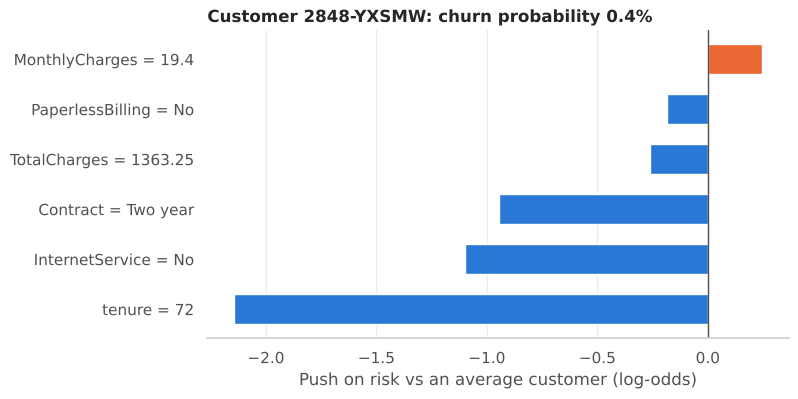

In [37]:
def explain(customer_id, n=6):
    row = df.set_index("customerID").loc[customer_id]
    c = contrib.loc[customer_id]
    c = c.reindex(c.abs().sort_values(ascending=False).index[:n]).sort_values()
    labels = [f"{col} = {row[col]}" for col in c.index]

    fig, ax = plt.subplots(figsize=(7.5, 0.5 * n + 1))
    ax.barh(labels, c.values, color=[CHURNED if v > 0 else STAYED for v in c.values], height=0.6)
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_title(f"Customer {customer_id}: churn probability {row['churn_prob']:.1%}")
    ax.set_xlabel("Push on risk vs an average customer (log-odds)")
    ax.grid(axis="y", visible=False); sns.despine(left=True); plt.show()

current = df[df["Churn"] == 0]                     # customers who are still with us
explain(current.sort_values("churn_prob").iloc[-1]["customerID"])        # highest risk
explain(current.sort_values("churn_prob").iloc[0]["customerID"])         # lowest risk

The first customer is a classic high-risk profile: new, month-to-month, fiber. The second is the opposite:
long tenure and a long contract keep them very safe. This is the kind of explanation a retention agent can act on.

## 5. The at-risk list for current customers
The business use of the model: score **customers who haven't left yet** (`Churn = 0`) and rank them.
We group scores into tiers and attach each person's **top 3 reasons** (features that push their risk up the most).

In [38]:
def top_reasons(customer_id, k=3):
    row = df.set_index("customerID").loc[customer_id]
    c = contrib.loc[customer_id]
    c = c[c > 0].sort_values(ascending=False).head(k)
    return "; ".join(f"{col}={row[col]}" for col in c.index)

current = df[df["Churn"] == 0].copy()
current["risk_tier"] = pd.cut(current["churn_prob"], [0, 0.3, 0.5, 0.7, 1.0],
                              labels=["Low", "Medium", "High", "Very high"])
current["top_reasons"] = current["customerID"].map(top_reasons)

summary = current.groupby("risk_tier", observed=True).agg(
    customers=("customerID", "size"), avg_prob=("churn_prob", "mean"),
    monthly_revenue=("MonthlyCharges", "sum"))
summary["avg_prob"] = summary["avg_prob"].round(2)
summary["monthly_revenue"] = summary["monthly_revenue"].round(0)
summary

,customers,avg_prob,monthly_revenue
risk_tier,,,
Low,2827,0.11,155100.0
Medium,945,0.40,56563.0
High,752,0.60,53635.0
Very high,650,0.79,51688.0


In [39]:
cols = ["customerID", "churn_prob", "risk_tier", "tenure", "Contract", "InternetService",
        "PaymentMethod", "MonthlyCharges", "top_reasons"]
at_risk = current.sort_values("churn_prob", ascending=False)[cols]
at_risk.to_csv("at_risk_customers.csv", index=False)
print(f"Saved at_risk_customers.csv ({len(at_risk):,} current customers, riskiest first)")
at_risk.head(15).style.format({"churn_prob": "{:.0%}", "MonthlyCharges": "${:.2f}"}).hide(axis="index")

Saved at_risk_customers.csv (5,174 current customers, riskiest first)


customerID,churn_prob,risk_tier,tenure,Contract,InternetService,PaymentMethod,MonthlyCharges,top_reasons
5150-ITWWB,93%,Very high,3,Month-to-month,Fiber optic,Electronic check,$94.85,tenure=3; InternetService=Fiber optic; Contract=Month-to-month
2545-EBUPK,92%,Very high,2,Month-to-month,Fiber optic,Electronic check,$84.05,tenure=2; InternetService=Fiber optic; Contract=Month-to-month
6630-UJZMY,91%,Very high,4,Month-to-month,Fiber optic,Electronic check,$83.25,tenure=4; InternetService=Fiber optic; Contract=Month-to-month
4847-TAJYI,91%,Very high,6,Month-to-month,Fiber optic,Electronic check,$89.35,tenure=6; InternetService=Fiber optic; Contract=Month-to-month
6350-XFYGW,91%,Very high,4,Month-to-month,Fiber optic,Electronic check,$94.75,tenure=4; InternetService=Fiber optic; Contract=Month-to-month
8161-QYMTT,91%,Very high,7,Month-to-month,Fiber optic,Electronic check,$94.10,tenure=7; InternetService=Fiber optic; Contract=Month-to-month
3320-VEOYC,91%,Very high,14,Month-to-month,Fiber optic,Electronic check,$95.60,tenure=14; InternetService=Fiber optic; Contract=Month-to-month
4115-NZRKS,91%,Very high,7,Month-to-month,Fiber optic,Electronic check,$89.15,tenure=7; InternetService=Fiber optic; Contract=Month-to-month
0021-IKXGC,91%,Very high,1,Month-to-month,Fiber optic,Electronic check,$72.10,tenure=1; InternetService=Fiber optic; Contract=Month-to-month
0187-QSXOE,91%,Very high,7,Month-to-month,Fiber optic,Electronic check,$89.00,tenure=7; InternetService=Fiber optic; Contract=Month-to-month


⚠️ **A caveat to be honest about:** this dataset is a single snapshot, so these "current" customers were also used to train the model.
In a real company you'd train on *last* quarter's outcomes and score *this* quarter's customers. That's how you'd deploy it.
Also remember that the model's probabilities run high on purpose (we used `class_weight="balanced"`), so treat them as a
**ranking** rather than an exact percentage.

## 6. Answering the business question
### Which customers are most likely to leave?
**New customers (under a year) on month-to-month contracts with fiber-optic internet**, especially those without
Online Security or Tech Support. The model can rank all current customers by risk, and the top 20% hold about half of future churners.

### Why?
| Driver | Effect | Likely reason |
|---|---|---|
| Short tenure | Strongest single factor | Haven't built a habit or relationship yet |
| Month-to-month contract | ~2× odds vs one-year, ~4× vs two-year | No commitment, easy to leave |
| Fiber-optic internet | ~2.3× odds vs DSL | Premium price, and possibly service-quality issues (worth investigating) |
| No security / support add-ons | Higher risk | Fewer "sticky" services, feel less supported |
| Electronic check | High in EDA, mostly explained by contract & tenure | Manual payment = a monthly moment to reconsider |

### What should the business do?
1. **Contract migration:** offer a discount for moving from month-to-month to a 1-year plan, targeted at the High / Very high tiers
2. **First-6-months onboarding:** welcome calls and check-ins, since this is when over half of leavers go
3. **Investigate fiber:** survey fiber customers on price and reliability. The model can't tell us *which* it is
4. **Bundle Online Security / Tech Support** as a free trial for at-risk customers
5. **Nudge towards auto-pay** (bank transfer / card) with a small incentive
6. **Measure it:** run retention offers as an A/B test (offer vs no offer) to prove they actually *cause* lower churn

## ✅ Project summary
| Stage | What we did | Key takeaway |
|---|---|---|
| 1. Cleaning | Fixed `TotalCharges`, tidied labels | Ask *why* data is missing before fixing it |
| 2. EDA | Churn rate by every feature | Contract, tenure, internet type and payment method stand out |
| 3. ML | 4 models, cross-validated | Simple logistic regression = complex models (AUC ≈ 0.84); class balance mattered more |
| 4. Interpretation | Coefficients, permutation importance, per-customer reasons | Tenure, contract and fiber drive risk; ranked list with reasons for each customer |

**Ideas to extend this project (great for a portfolio):**
- Add **SHAP** values to explain the tree models, and compare with the logistic regression explanations
- Build a **cost-based threshold**: pick the cut-off that maximises (revenue saved − cost of offers)
- Try **feature engineering**: number of services, "new & month-to-month" flag, charges per service
- Build a **Streamlit dashboard** where someone can enter a customer's details and see the risk and reasons